# Figure 3 revision analysis: pooled myofiber bulk RNA-seq

This notebook documents the revised analysis used for Figure 3g–i of the DMD p16
reporter rat study. It includes all 17 libraries from five rats and compares
GFP-positive with GFP-negative pooled myofibers using a paired design.

For each library, gene-level TPM values are converted to scaledTPM counts before
available left- and right-side libraries are summed within each rat and GFP group.
The summed values are then rounded to integers. The analysis uses PyDESeq2 for
differential expression, variance-stabilizing transformation for PCA, and GSEApy
for preranked enrichment of rat Reactome and KEGG gene sets.

The saved primary analysis identified two differentially expressed genes and 49
gene sets with Benjamini–Hochberg-adjusted P < 0.05. Figure 3i shows ten selected
significant gene sets from the 1,310 tested sets. These saved results provide a
reference for reproduction; the code does not select settings to reach these counts.

The earlier estimated-count analysis is documented in `comparison/`. The final
analysis uses the scaledTPM input described below. All original sample identifiers
are retained; `PoorQC` is a legacy sample-name label, not an exclusion criterion.

The default `MODE = "reanalyze"` recomputes the analysis from the supplied inputs.
Use `MODE = "replot"` to reproduce the figures from the supplied result snapshots.
See `README.md` for setup, file descriptions, and the revision record.


## Analysis methods and reproducibility

This notebook reproduces the PCA, volcano, and GSEA figures from the fixed
2026-10-09 reanalysis. All 17 original libraries are included. Each library's
gene-level TPM is converted using the **scaledTPM formula** implemented in Python:

`scaledCount_gs = TPM_gs / sum_g(TPM_gs) * sum_g(originalEstimatedCount_gs)`.

Available left/right libraries are then summed within each animal and GFP group,
and rounded once, giving ten profiles from **five paired biological replicates**.
TPM is not supplied directly to PyDESeq2. No transcript-length offset is added
after this conversion. The tximport package is not invoked.

**Modes:** `replot` uses the checksum-verified frozen results;
`reanalyze` (default) repeats inference from the original Counts and TPM inputs.
Both retain exactly the same settings, references, and seed. The supplied .py
contains the same code cells. Run from this directory after installing requirements.

The primary analysis uses PyDESeq2 0.5.4, design `~ animal + condition`, parametric
dispersion fit, Wald contrast GFP+ versus GFP−, and genome-wide BH-adjusted P < 0.05.
Genes need total aggregated count >= 10. PCA uses design-free VST and the 500 most
variable genes. GSEApy 1.3.1 uses all finite signed Wald statistics, multilevel
preranking, weight 1, sample size 1001, epsilon 1e-10, seed 20260915, and the same
frozen rat Reactome/KEGG sets with 15–500 represented genes. Nominal P values are
BH-adjusted over all tested sets together. Results are not forced to a target count.

Numerical-convergence sensitivity is supplied separately in `audit/`. It removes
genes with any failed convergence flag and repeats the same GSEA settings.
The primary ranking includes all finite Wald statistics, as in the earlier analysis.
Re-running a fixed calculation tests reproducibility of the calculation; it does
not establish biological replication or exclude all technical confounding.

Updated 2026-10-16: the selected GSEA panel shows ten pathways, all with
BH-adjusted P < 0.05 across all 1,310 tested sets. The two nonsignificant
cardiomyopathy sets have been removed from the display. The complete significant-set
plot and all tested numerical results are unchanged. This is a plotting-only update. Enrichment identifies associations,
not pathway activation, cellular senescence, or causal effects. PCA ellipses are
descriptive data contours, not confidence intervals or tests of group separation.

References: [tximport vignette](https://bioconductor.org/packages/release/bioc/vignettes/tximport/inst/doc/tximport.html),
[scaledTPM implementation](https://github.com/thelovelab/tximport/blob/devel/R/helper.R).


## Setup


In [1]:
from pathlib import Path
import json, hashlib, textwrap, warnings, importlib.metadata, sys
import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import false_discovery_control
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import gseapy as gp

MODE = "reanalyze"  # "replot" or "reanalyze"
BASE = Path.cwd()
if not (BASE / "manifest.json").exists():
    raise FileNotFoundError("Run from the package directory containing manifest.json and the data/, references/, and snapshot/ subdirectories.")
assert MODE in {"replot", "reanalyze"}
OUT = BASE / ("results_" + MODE)
OUT.mkdir(exist_ok=True)
SEED = 20260915
THREADS = 4
ALPHA = 0.05
MIN_TOTAL_COUNT = 10
TOP_VARIABLE_GENES = 500
GSEA_MIN_SIZE, GSEA_MAX_SIZE = 15, 500
GSEA_SAMPLE_SIZE = 1001
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,
    'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none',
    'figure.dpi':160,'savefig.dpi':250})
blue, orange = '#2477B4', '#D85C35'
def save(fig, name):
    for ext in ['png', 'svg', 'pdf']:
        fig.savefig(OUT / f'{name}.{ext}', bbox_inches='tight', facecolor='white')
    if 'ipykernel' in sys.modules:
        plt.show()
    plt.close(fig)


## Verify original inputs


In [2]:
manifest = json.loads((BASE / "manifest.json").read_text())
for relative, expected in manifest.items():
    actual = hashlib.sha256((BASE / relative).read_bytes()).hexdigest()
    if actual != expected:
        raise ValueError(f"Input differs from the frozen analysis: {relative}")
versions = {p: importlib.metadata.version(p) for p in
    ['pydeseq2','gseapy','numpy','scipy','pandas','matplotlib']}
(OUT / 'software_versions.json').write_text(json.dumps(versions, indent=2))
print('Input checksums verified. Mode:', MODE)
print(versions)
counts = pd.read_csv(BASE / 'data/counts_all_samples.csv.gz', index_col=0, float_precision='round_trip')
tpm = pd.read_csv(BASE / 'data/tpm_all_samples.csv.gz', index_col=0, float_precision='round_trip')
assert tpm.index.equals(counts.index) and tpm.columns.equals(counts.columns)
assert np.isfinite(tpm.to_numpy()).all() and (tpm.to_numpy() >= 0).all()
assert (tpm.sum() > 0).all() and (counts.sum() > 0).all()
meta = pd.read_csv(BASE / 'data/sample_metadata.csv', index_col=0, dtype={'animal':str})
assert counts.index.is_unique and counts.columns.is_unique and meta.index.is_unique
assert set(counts.columns) == set(meta.index)
assert np.isfinite(counts.to_numpy()).all() and (counts.to_numpy() >= 0).all()
assert len(meta) == 17 and meta.animal.nunique() == 5
assert set(meta.condition) == {'negative','positive'}
for name, row in meta.iterrows():
    assert name.startswith(row.animal + row.side)
    assert name.endswith('+' if row.condition == 'positive' else '-')
print('Input matrix:', counts.shape, '(genes x libraries)')


Input checksums verified. Mode: reanalyze
{'pydeseq2': '0.5.4', 'gseapy': '1.3.1', 'numpy': '2.3.5', 'scipy': '1.18.1', 'pandas': '3.0.5', 'matplotlib': '3.11.2'}
Input matrix: (23978, 17) (genes x libraries)


## Convert each library, then aggregate


In [3]:
# tximport's scaledTPM formula, implemented here in Python (not a tximport invocation).
# Apply to each original library BEFORE combining sides; never input TPM directly to DESeq2.
scaled = tpm.div(tpm.sum(axis=0), axis=1).mul(counts.sum(axis=0), axis=1)
assert np.allclose(scaled.sum(axis=0), counts.sum(axis=0), rtol=1e-12)
scaled.to_csv(OUT / 'scaledTPM_library_counts.csv.gz')
meta['aggregate'] = meta.animal + '_' + meta.condition
c = scaled[meta.index].T.groupby(meta['aggregate']).sum().round().astype('int64')
a = meta.groupby('aggregate')[['animal','condition']].first().loc[c.index]
membership = meta.groupby('aggregate').apply(lambda x: ';'.join(x.index), include_groups=False)
aggregation = a.join(membership.rename('source_samples'))
assert (a.groupby('animal').condition.nunique() == 2).all()
assert len(a) == 10
aggregation.to_csv(OUT / 'aggregation.csv')
c.to_csv(OUT / 'aggregated_counts_before_filter.csv.gz')
c = c.loc[:, c.sum(axis=0) >= MIN_TOTAL_COUNT]
c.to_csv(OUT / 'aggregated_counts_tested.csv.gz')
print(aggregation.to_string())
print('Tested genes:', c.shape[1])


            animal condition            source_samples
aggregate                                             
10_negative     10  negative         10L_GFP-;10R_GFP-
10_positive     10  positive  10R_GFP+;10L_PoorQC_GFP+
11_negative     11  negative         11L_GFP-;11R_GFP-
11_positive     11  positive         11L_GFP+;11R_GFP+
12_negative     12  negative                  12L_GFP-
12_positive     12  positive                  12L_GFP+
13_negative     13  negative                  13R_GFP-
13_positive     13  positive        13R-_GFP+;13L_GFP+
15_negative     15  negative  15R_PoorQC_GFP-;15L_GFP-
15_positive     15  positive         15L_GFP+;15R_GFP+
Tested genes: 23015


## Paired differential expression


In [4]:
annotation = pd.read_csv(BASE / 'references/gene_annotation.csv').set_index('gene_id')
if MODE == 'reanalyze':
    dds = DeseqDataSet(counts=c, metadata=a, design='~ animal + condition',
                       fit_type='parametric', n_cpus=THREADS, quiet=True)
    design = dds.obsm['design_matrix']
    assert np.linalg.matrix_rank(design) == design.shape[1]
    dds.deseq2()
    gene_diagnostics = dds.var.copy()
    ds = DeseqStats(dds, contrast=['condition','positive','negative'],
                    alpha=ALPHA, n_cpus=THREADS, quiet=True)
    ds.summary()
    norm_counts = pd.DataFrame(dds.layers['normed_counts'], index=c.index, columns=c.columns).T
    result = ds.results_df.copy()
    result.index.name = 'gene_id'
    de = result.join(annotation[['symbol','description']]).reset_index()
else:
    de = pd.read_csv(BASE / 'snapshot/DE_annotated.csv')
    norm_counts = pd.read_csv(BASE / 'snapshot/normalized_counts.csv.gz', index_col=0)
    gene_diagnostics = pd.read_csv(BASE / 'snapshot/gene_diagnostics.csv', index_col=0)
gene_diagnostics.to_csv(OUT / 'gene_diagnostics.csv')
convergence_cols = [k for k in ['_LFC_converged','_genewise_converged','_MAP_converged']
                    if k in gene_diagnostics]
failed_ids = gene_diagnostics.index[(gene_diagnostics[convergence_cols] == False).any(axis=1)]
print('Genes with any nonconvergence flag:', len(failed_ids))
assert de.gene_id.is_unique and set(de.gene_id) == set(c.columns)
de.to_csv(OUT / 'DE_annotated.csv', index=False)
significant = de[de.padj < ALPHA]
significant.to_csv(OUT / 'significant_genes.csv', index=False)
print('Significant genes:', len(significant),
      '; higher in GFP+:', int((significant.log2FoldChange > 0).sum()),
      '; lower in GFP+:', int((significant.log2FoldChange < 0).sum()))

assert norm_counts.index.equals(pd.Index(c.columns))
assert norm_counts.columns.equals(pd.Index(c.index))
norm_counts.to_csv(OUT / 'normalized_counts.csv.gz')


Genes with any nonconvergence flag: 169
Significant genes: 2 ; higher in GFP+: 0 ; lower in GFP+: 2


## Preranked GSEA


In [5]:
ranks = de.set_index('gene_id').stat
ranks = ranks[np.isfinite(ranks)].copy()
ranks.index = ranks.index.str.replace(r'\.\d+$', '', regex=True)
assert ranks.index.is_unique
ranks = ranks.sort_values(ascending=False, kind='stable')
ranks.to_csv(OUT / 'ranked_genes.csv', header=['Wald_statistic'])
sets = json.loads((BASE / 'references/rat_gene_sets.json').read_text())
details = json.loads((BASE / 'references/rat_pathway_names.json').read_text())
universe = set(ranks.index)
eligible = {k:v for k,v in sets.items()
            if GSEA_MIN_SIZE <= len(set(v) & universe) <= GSEA_MAX_SIZE}
if MODE == 'reanalyze':
    enrichment = gp.prerank(rnk=ranks, gene_sets=eligible, threads=THREADS,
        min_size=GSEA_MIN_SIZE, max_size=GSEA_MAX_SIZE, method='multilevel',
        sample_size=GSEA_SAMPLE_SIZE, permutation_num=1000, eps=1e-10, outdir=None, seed=SEED,
        verbose=True, no_plot=True, weight=1)
    g = enrichment.res2d.copy()
    g['BH_padj_all_pathways'] = false_discovery_control(
        pd.to_numeric(g['NOM p-val']).to_numpy(), method='bh')
    for field in ['pathway','database','url']:
        g[field] = g.Term.map(lambda k: details[k][field])
    g['overlap_size'] = g.Term.map(lambda k: len(set(eligible[k]) & universe))
    symbols = dict(zip(annotation.ensembl_stable,
                       annotation.symbol.fillna(annotation.ensembl_stable)))
    g['leading_edge_symbols'] = g.Lead_genes.map(
        lambda s: ';'.join(str(symbols.get(x,x)) for x in s.split(';')))
    g = g.sort_values(['BH_padj_all_pathways','NOM p-val','Term'])
else:
    g = pd.read_csv(BASE / 'snapshot/GSEA_all_pathways.csv')
assert set(g.Term) == set(eligible)
assert np.allclose(false_discovery_control(g['NOM p-val'].to_numpy()),
                   g.BH_padj_all_pathways)
g.to_csv(OUT / 'GSEA_all_pathways.csv', index=False)
sg = g[g.BH_padj_all_pathways < ALPHA].copy()
sg.to_csv(OUT / 'GSEA_significant_pathways.csv', index=False)
print('Ranked genes:', len(ranks), '; tested pathways:', len(g),
      '; significant pathways:', len(sg))


Ranked genes: 23015 ; tested pathways: 1310 ; significant pathways: 49


2026-10-09 21:00:11,771 [WARNING] Duplicated values found in preranked stats: 1.78% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-09 21:00:11,773 [INFO] Parsing data files for GSEA.............................
2026-10-09 21:00:11,806 [INFO] 0000 gene_sets have been filtered out when max_size=500 and min_size=15
2026-10-09 21:00:11,806 [INFO] 1310 gene_sets used for further statistical testing.....
2026-10-09 21:00:11,806 [INFO] Start to run GSEA...Might take a while..................
2026-10-09 21:01:15,090 [INFO] Congratulations. GSEApy runs successfully................



## Design-free VST and PCA


In [6]:
if MODE == 'reanalyze':
    vst_dds = DeseqDataSet(counts=c, metadata=a, design='~ animal + condition',
                          n_cpus=THREADS, quiet=True)
    vst_dds.vst(use_design=False)
    v = pd.DataFrame(vst_dds.layers['vst_counts'], index=c.index, columns=c.columns)
else:
    v = pd.read_csv(BASE / 'snapshot/VST_counts.csv.gz', index_col=0)
assert v.index.equals(c.index) and v.columns.equals(c.columns)
v.to_csv(OUT / 'VST_counts.csv.gz')
top = v.var(axis=0).nlargest(TOP_VARIABLE_GENES).index
pd.Series(top, name='gene_id').to_csv(OUT / 'PCA_selected_genes.csv', index=False)
x = v[top].to_numpy(); x = x - x.mean(axis=0)
u, s, vt = np.linalg.svd(x, full_matrices=False)
pc = u[:,:2] * s[:2]
variance = s*s / (s*s).sum() * 100
p = a.copy(); p['PC1'] = pc[:,0]; p['PC2'] = pc[:,1]
p.to_csv(OUT / 'PCA_coordinates.csv')
print('PC1 and PC2 variance (%):', variance[:2])
# PCA component signs can reverse across numerical libraries without changing distances.


PC1 and PC2 variance (%): [40.73302976 16.00344155]


## PCA figure


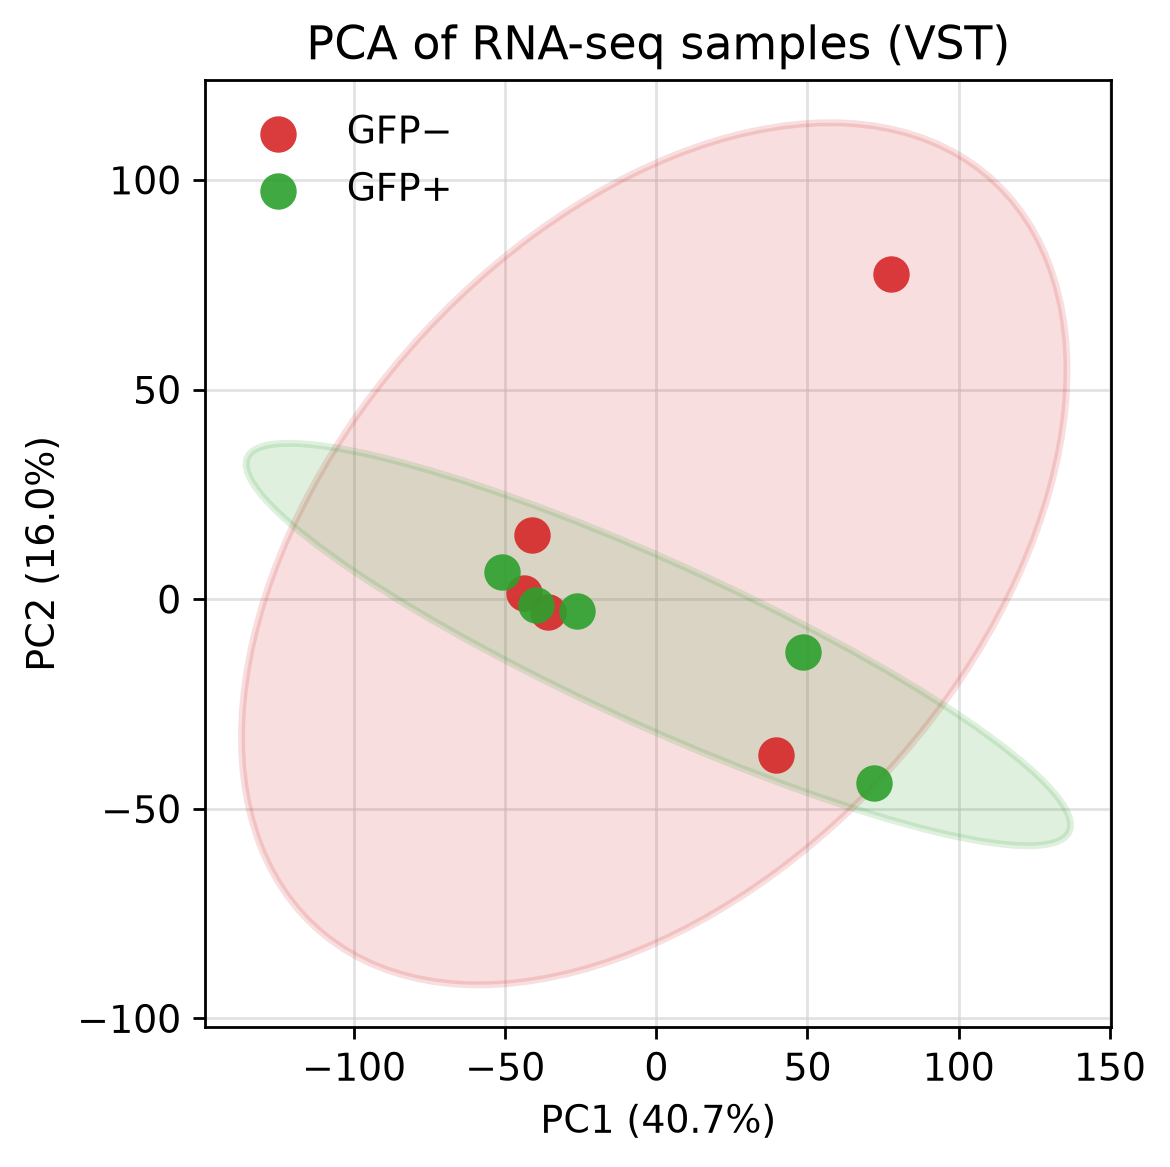

In [7]:
from matplotlib.patches import Ellipse

# Original notebook style; current animal-level VST coordinates retained.
COLOR_MAP = {'negative':'#D62728', 'positive':'#2CA02C'}
DOT_SIZE = 110
ELLIPSE_ALPHA = 0.15
ELLIPSE_LW = 2.0
def add_data_ellipse(ax, x, y, color):
    # Gaussian 95% data ellipse: descriptive covariance contour,
    # NOT a confidence interval for a group mean or a test of separation.
    xy = np.column_stack([x, y])
    if len(xy) < 3:
        return
    cov = np.cov(xy, rowvar=False)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = np.maximum(vals[order], 0), vecs[:,order]
    width, height = 2 * np.sqrt(vals * 5.991)
    angle = np.degrees(np.arctan2(vecs[1,0], vecs[0,0]))
    ax.add_patch(Ellipse(xy.mean(axis=0), width, height, angle=angle,
        facecolor=color, edgecolor=color, alpha=ELLIPSE_ALPHA,
        lw=ELLIPSE_LW, zorder=1))

fig, ax = plt.subplots(figsize=(4.8,4.8))
for condition, label in [('negative','GFP−'),('positive','GFP+')]:
    group = p[p.condition == condition]
    ax.scatter(group.PC1, group.PC2, s=DOT_SIZE,
        color=COLOR_MAP[condition], label=label, alpha=.9,
        linewidths=0, zorder=3)
    add_data_ellipse(ax, group.PC1, group.PC2, COLOR_MAP[condition])
ax.set_xlabel(f'PC1 ({variance[0]:.1f}%)')
ax.set_ylabel(f'PC2 ({variance[1]:.1f}%)')
ax.set_title('PCA of RNA-seq samples (VST)')
for spine in ax.spines.values(): spine.set_visible(True)
ax.set_axisbelow(True)
ax.grid(True, which='both', axis='both', color='#D0D0D0', linewidth=.8, alpha=.6)
ax.legend(frameon=False)
fig.tight_layout()
save(fig,'PCA_all_samples')


## Volcano figures and all DEG labels


DEGs: 2 ; higher: 0 ; lower: 2


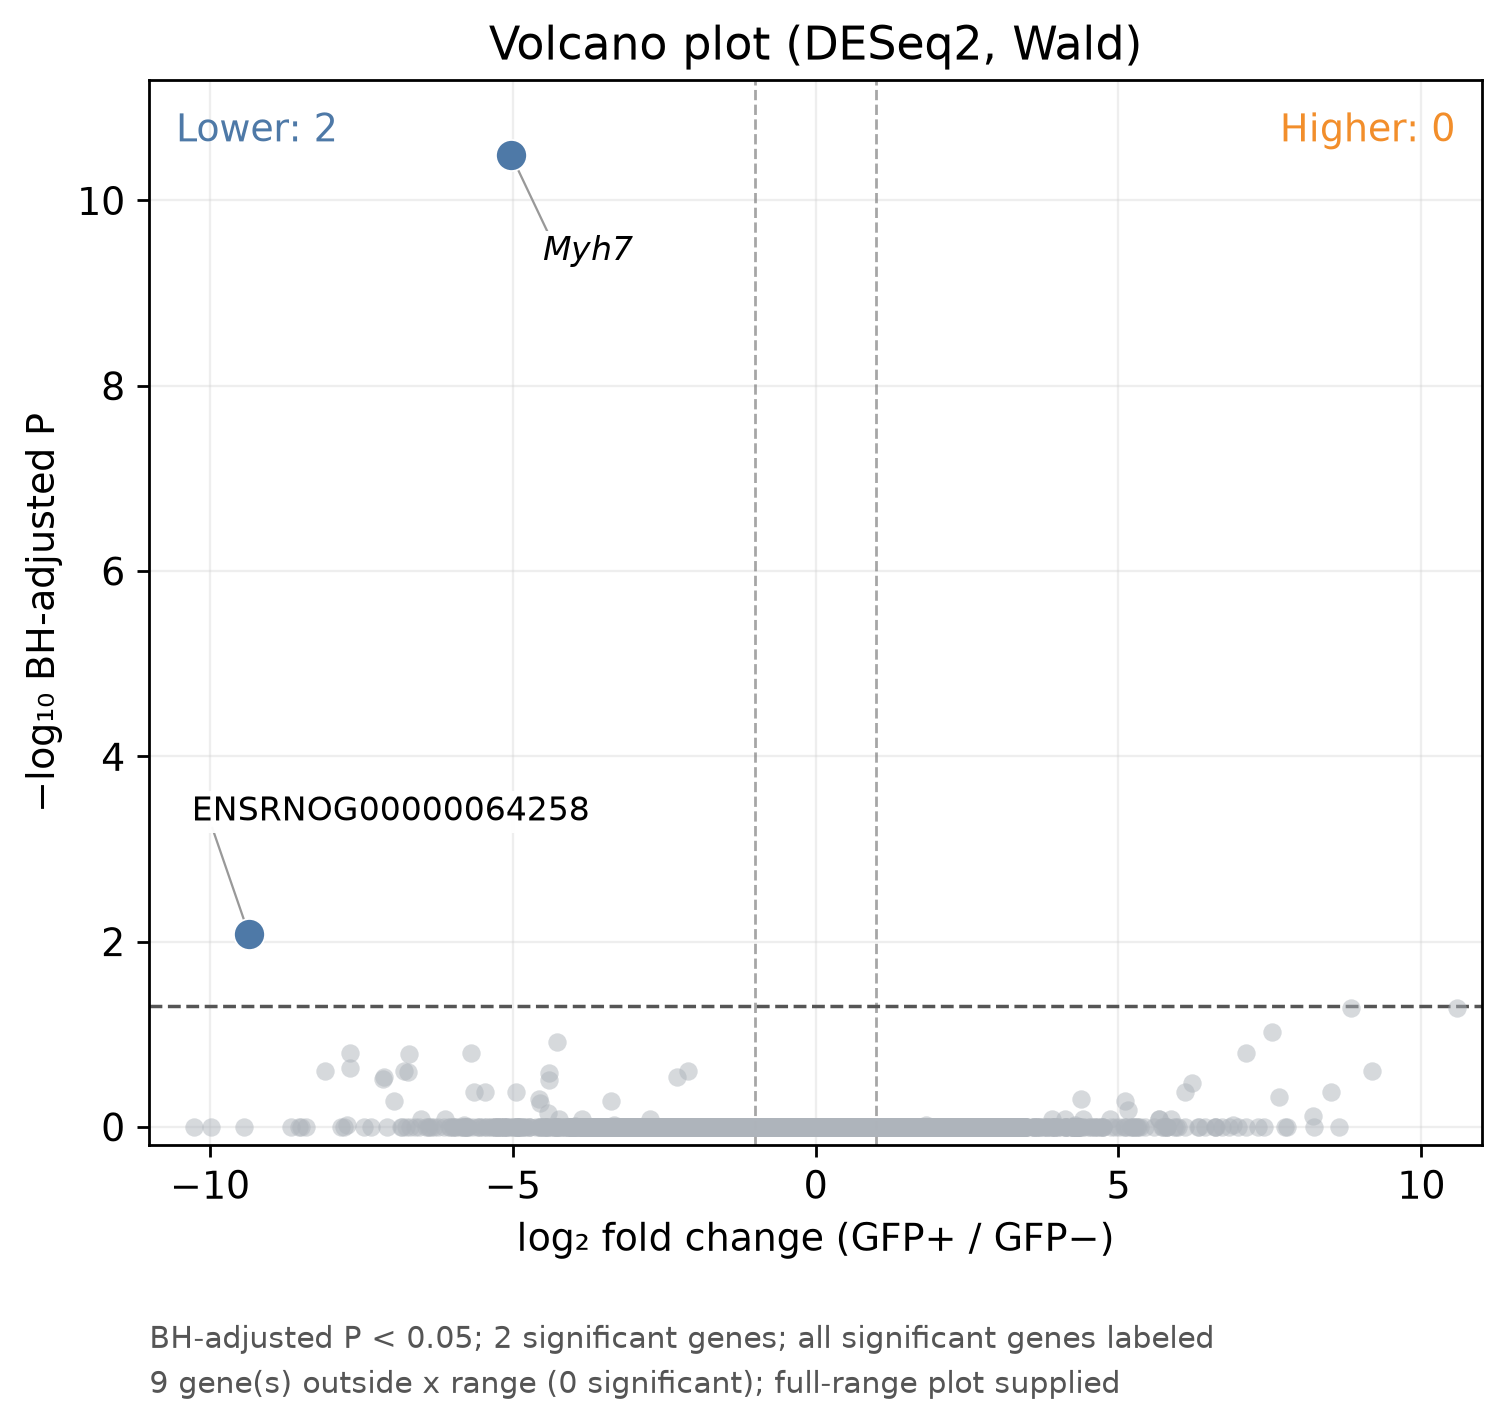

In [8]:
# Larger points for reviewer-requested readability; all DE results unchanged.
POINT_SIZE_NS, POINT_SIZE_SIG = 28, 80
COLOR_NS, COLOR_UP, COLOR_DN = '#AEB4BB', '#F28E2B', '#4E79A7'
LOG2FC_GUIDE = 1.0  # Magnitude guide only; significance uses BH-adjusted P.
de.to_csv(OUT / 'DE_plot_data.csv', index=False)
d = de[np.isfinite(de.padj) & np.isfinite(de.log2FoldChange)].copy()
d['neglog10'] = -np.log10(d.padj.clip(lower=1e-300))
sig = d.padj < ALPHA
up = sig & (d.log2FoldChange > 0)
down = sig & (d.log2FoldChange < 0)

def volcano_base():
    fig, ax = plt.subplots(figsize=(6.5,6))
    ax.scatter(d.loc[~sig,'log2FoldChange'],d.loc[~sig,'neglog10'],
        s=POINT_SIZE_NS,alpha=.5,c=COLOR_NS,linewidths=0,zorder=2)
    for mask,color in [(up,COLOR_UP),(down,COLOR_DN)]:
        ax.scatter(d.loc[mask,'log2FoldChange'],d.loc[mask,'neglog10'],
            s=POINT_SIZE_SIG,alpha=1,c=color,edgecolors='white',linewidths=.5,zorder=4)
    for xpos in [-LOG2FC_GUIDE,LOG2FC_GUIDE]:
        ax.axvline(xpos,ls='--',lw=.8,c='#777777',alpha=.65,zorder=1)
    ax.axhline(-np.log10(ALPHA),ls='--',lw=1,c='#555555',zorder=1)
    ax.set(xlabel='log₂ fold change (GFP+ / GFP−)',ylabel='−log₁₀ BH-adjusted P',
           title='Volcano plot (DESeq2, Wald)',ylim=(-.2,10.6))
    for spine in ax.spines.values():spine.set_visible(True)
    ax.set_axisbelow(True)
    ax.grid(True,color='#D0D0D0',linewidth=.65,alpha=.35)
    ax.text(.02,.97,f'Lower: {int(down.sum())}',color=COLOR_DN,
            transform=ax.transAxes,va='top',fontsize=11)
    ax.text(.98,.97,f'Higher: {int(up.sum())}',color=COLOR_UP,
            transform=ax.transAxes,ha='right',va='top',fontsize=11)
    fig.subplots_adjust(left=.15,right=.97,bottom=.19,top=.90)
    return fig,ax

# Full-range companion preserves the nonsignificant, very large fold-change point.
fig,ax=volcano_base()
ax.set_ylim(-.2,max(10.6,float(d.neglog10.max())+.8))
save(fig,'Volcano_full_range')

# Presentation panel: explicit x window; no tests or gene values are changed.
fig,ax=volcano_base()
ax.set_xlim(-11,11)
ax.set_xticks([-10,-5,0,5,10])
ax.set_ylim(-.2,max(10.6,float(d.neglog10.max())+.8))
# Label every significant gene; use the stable Ensembl ID when no symbol exists.
label_positions={
    'ENSRNOG00000064258':(-10.3,3.4),
    'Myh7':(-4.5,9.45),
    'ENSRNOG00000064949':(-10.3,7.4),
    'Cep126':(-10.3,5.9),
    'Krt2':(-10.3,4.6),
    'Kirrel2':(-10.3,3.3),
    'LOC146719387':(-4.8,6.3),
    'Coro2b':(-4.8,5.0),
    'Myh6':(-3.2,3.8),
    'Ina':(-3.2,2.6),
    'C11h3orf70':(5.0,3.5),
    'Tubg2':(5.0,2.6),
}
labels=d.loc[sig].copy()
labels['display_label']=labels.symbol.fillna(
    labels.gene_id.str.replace(r'\.\d+$','',regex=True))
labels.to_csv(OUT / 'Volcano_labeled_genes.csv',index=False)
# Draw leader lines below text so they cannot obscure any gene label.
for i,(_,row) in enumerate(labels.iterrows()):
    tx,ty=label_positions.get(row.display_label,
        (float(np.clip(row.log2FoldChange,-9.5,6)),2.8+.6*i))
    ax.annotate('',(row.log2FoldChange,row.neglog10),xytext=(tx+.3,ty-.1),
        arrowprops=dict(arrowstyle='-',color='#999999',lw=.65),zorder=3)
for i,(_,row) in enumerate(labels.iterrows()):
    tx,ty=label_positions.get(row.display_label,
        (float(np.clip(row.log2FoldChange,-9.5,6)),2.8+.6*i))
    ax.text(tx,ty,row.display_label,fontsize=9.5,
        fontstyle='normal' if pd.isna(row.symbol) else 'italic',
        ha='left',va='center',zorder=6,
        bbox=dict(facecolor='white',edgecolor='none',pad=1.2,alpha=.96))
outside=d[d.log2FoldChange.abs()>11]
outside_sig=int((outside.padj<ALPHA).sum())
fig.text(.15,.055,f'BH-adjusted P < {ALPHA}; {int(sig.sum())} significant genes; all significant genes labeled',fontsize=8.5,color='#555555')
fig.text(.15,.025,f'{len(outside)} gene(s) outside x range ({outside_sig} significant); full-range plot supplied',fontsize=8.5,color='#555555')
save(fig,'Volcano_all_samples')
print('DEGs:',int(sig.sum()),'; higher:',int(up.sum()),'; lower:',int(down.sum()))


## GSEA lollipop figures


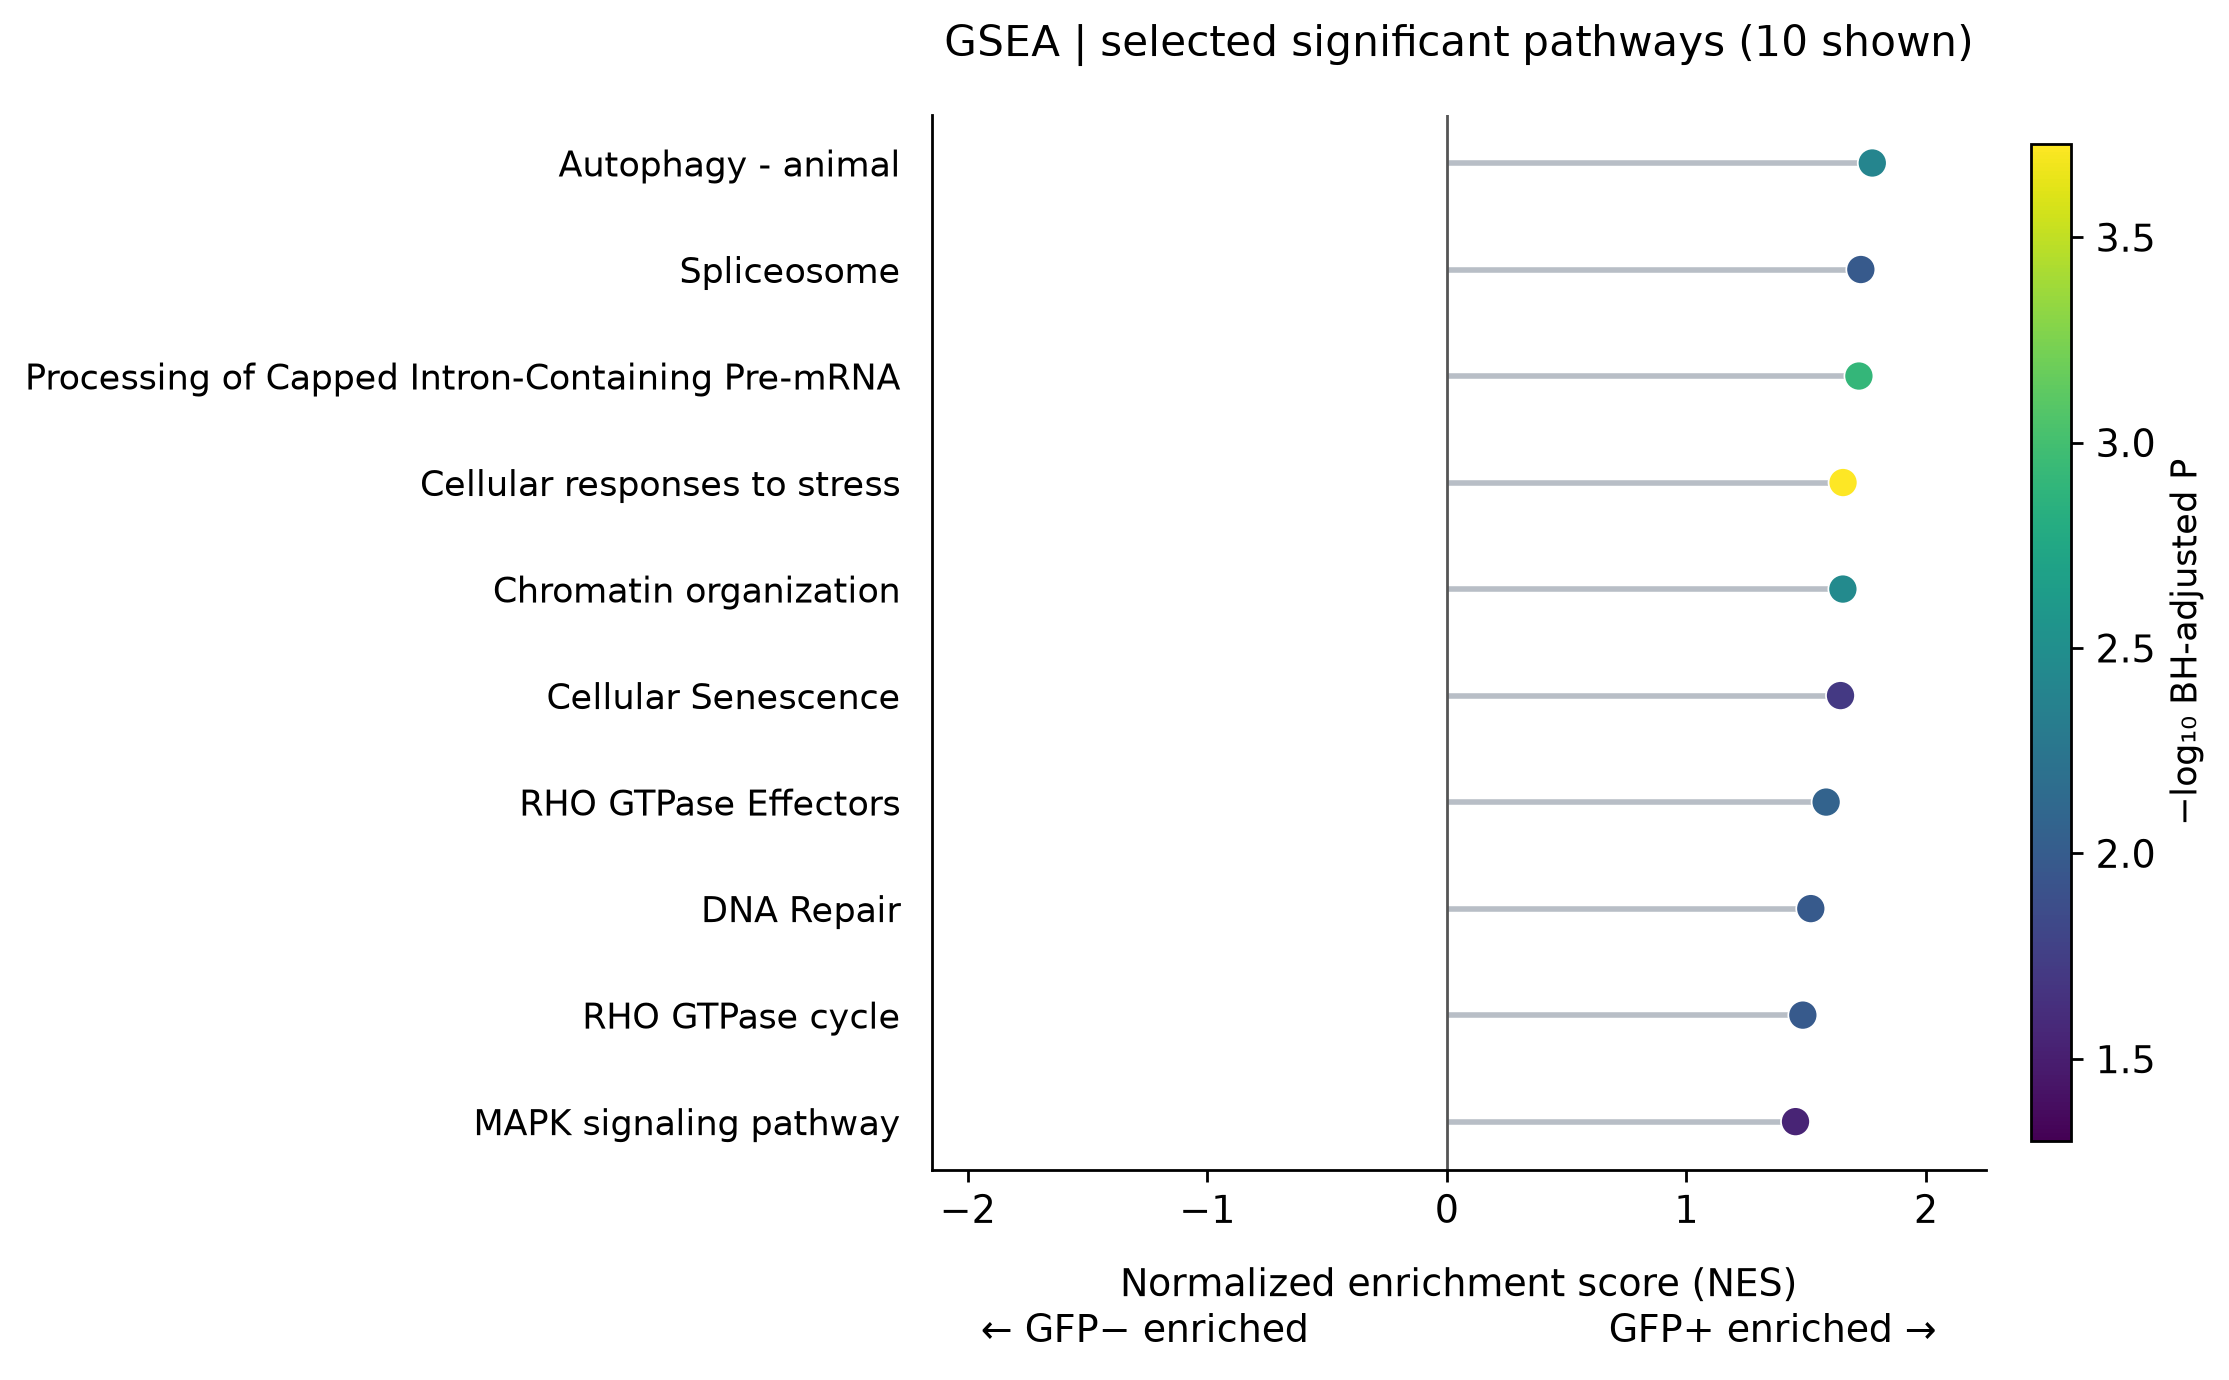

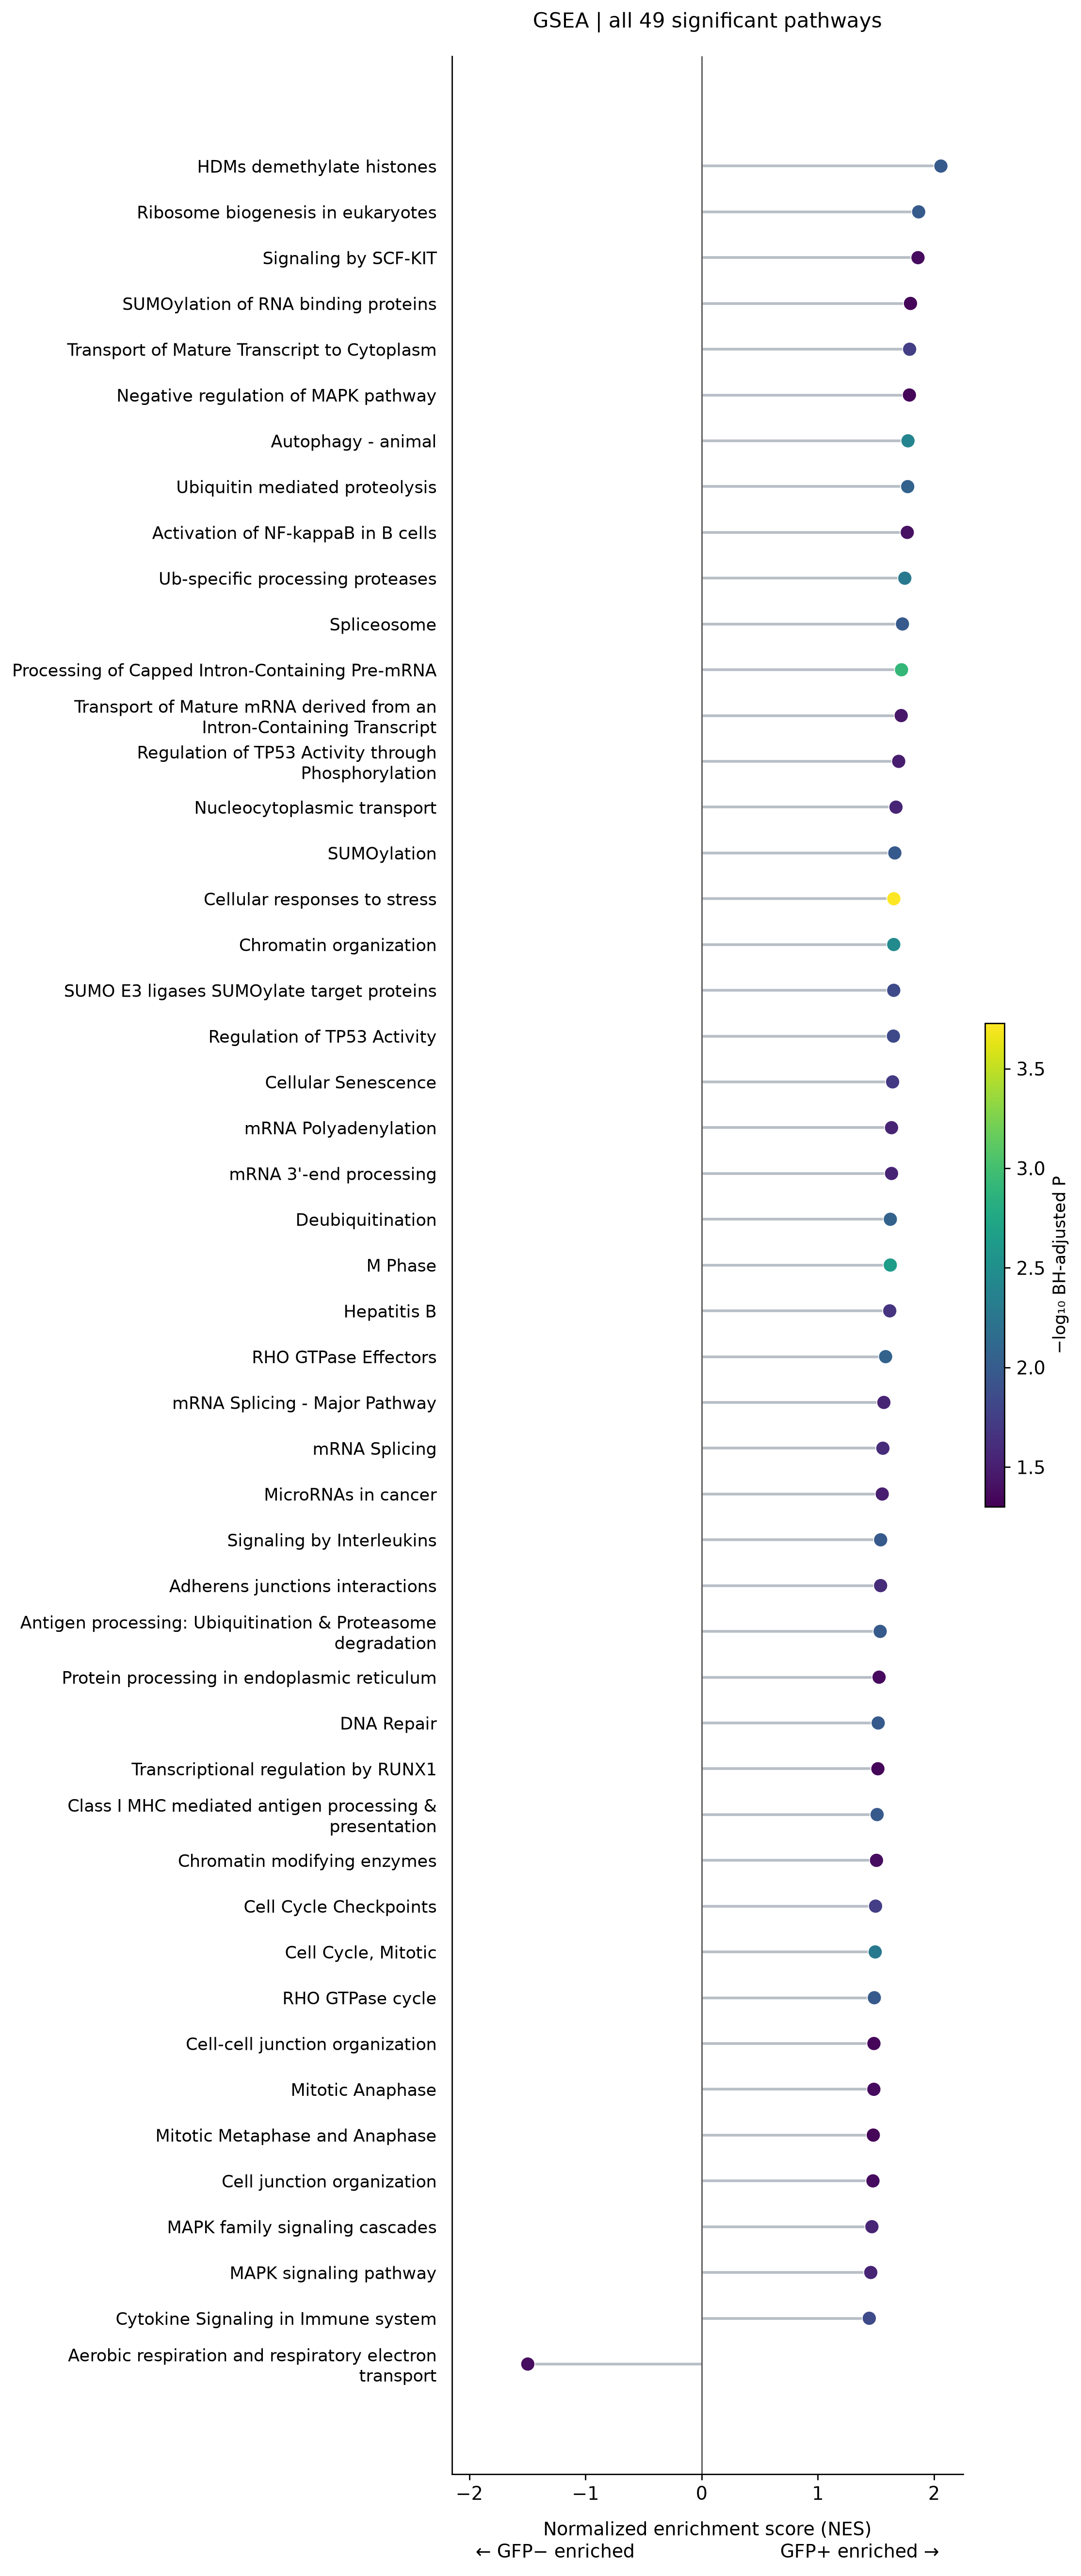

In [9]:
g.to_csv(OUT/'GSEA_all_pathways.csv',index=False)
sg=g[g.BH_padj_all_pathways<.05].copy()
selected=['R-RNO-2262752','R-RNO-72203','rno03040','R-RNO-4839726','rno04140','R-RNO-195258','R-RNO-73894','R-RNO-9012999','R-RNO-2559583','rno04010']
# Display the existing selected pathways only when their globally adjusted P < ALPHA.
# BH adjustment was performed across ALL tested sets before this display filter.
sel=g[g.Term.str.split(':').str[-1].isin(selected) &
      (g.BH_padj_all_pathways < ALPHA)].copy().sort_values('NES',ascending=False)
# Fig. 3i is an illustrative subset, not the complete list of significant pathways.
assert len(sel) == 10 and (sel.BH_padj_all_pathways < ALPHA).all()
def lollipop(data,name,title):
    data=data.sort_values('NES',ascending=False).reset_index(drop=True)
    assert (data.BH_padj_all_pathways < ALPHA).all()
    data.to_csv(OUT/f'{name}_data.csv',index=False)
    fig,ax=plt.subplots(figsize=(10.6,max(5.7,len(data)*(.55 if len(data)>15 else .40))))
    yy=np.arange(len(data))
    ax.hlines(yy,0,data.NES,color='#B8BEC6',lw=1.6,zorder=1)
    is_sig = (data.BH_padj_all_pathways < ALPHA).to_numpy()
    vmax = max(2.8, float(-np.log10(data.BH_padj_all_pathways.min())))
    dots=ax.scatter(data.loc[is_sig,'NES'],yy[is_sig],
        c=-np.log10(data.loc[is_sig,'BH_padj_all_pathways']),s=70,cmap='viridis',
        vmin=1.3,vmax=vmax,zorder=3,edgecolors='white',linewidth=.5)
    labels=[textwrap.fill(t.replace(' - Rattus norvegicus (rat)',''),47) for t in data.pathway]
    ax.set_yticks(yy,labels,fontsize=10);ax.invert_yaxis();ax.tick_params(axis='y',length=0,pad=9)
    ax.axvline(0,c='#555555',lw=.8)
    ax.set_xlim(-2.15,2.25);ax.set_xticks([-2,-1,0,1,2]);ax.set_xlabel('Normalized enrichment score (NES)\n← GFP− enriched                         GFP+ enriched →',labelpad=9)
    ax.set_title(title,pad=17,fontsize=12)
    cb=fig.colorbar(dots,ax=ax,pad=.04,fraction=.035,aspect=25)
    cb.set_label('−log₁₀ BH-adjusted P',fontsize=10)
    fig.subplots_adjust(left=.47,right=.90,bottom=.16,top=.90)
    save(fig,name)
if len(sel): lollipop(sel,'GSEA_selected_pathways',
    f'GSEA | selected significant pathways ({len(sel)} shown)')
if len(sg): lollipop(sg,'GSEA_all_significant_pathways',f'GSEA | all {len(sg)} significant pathways')


## Reproducibility summary


In [10]:
snapshot_de = pd.read_csv(BASE / 'snapshot/DE_annotated.csv').set_index('gene_id')
current_de = de.set_index('gene_id').reindex(snapshot_de.index)
snapshot_gsea = pd.read_csv(BASE / 'snapshot/GSEA_all_pathways.csv').set_index('Term')
current_gsea = g.set_index('Term').reindex(snapshot_gsea.index)
report = {
    'mode': MODE, 'libraries': len(meta), 'animals': a.animal.nunique(),
    'design': '~ animal + condition', 'contrast': 'positive / negative',
    'significant_genes': int((de.padj < ALPHA).sum()),
    'tested_pathways': len(g), 'significant_pathways': len(sg),
    'PCA_variance_percent': variance[:2].tolist(),
    'DE_stat_max_absolute_difference_from_snapshot': float(
        (current_de.stat-snapshot_de.stat).abs().max()),
    'GSEA_BH_max_absolute_difference_from_snapshot': float(
        (current_gsea.BH_padj_all_pathways-snapshot_gsea.BH_padj_all_pathways).abs().max()),
    'seed': SEED, 'GSEA_sample_size': GSEA_SAMPLE_SIZE,
    'input_method': 'scaledTPM formula per library, before animal aggregation',
    'any_nonconverged_genes': len(failed_ids),
    'significant_nonconverged_genes': sorted(set(failed_ids) & set(significant.gene_id)),
    'note': 'Frozen scaledTPM snapshot: 2 DEGs, 49 significant pathways. These are reference results, not selection targets.'
}
(OUT / 'run_summary.json').write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))


{
  "mode": "reanalyze",
  "libraries": 17,
  "animals": 5,
  "design": "~ animal + condition",
  "contrast": "positive / negative",
  "significant_genes": 2,
  "tested_pathways": 1310,
  "significant_pathways": 49,
  "PCA_variance_percent": [
    40.73302976293934,
    16.003441553193028
  ],
  "DE_stat_max_absolute_difference_from_snapshot": 4.440892098500626e-16,
  "GSEA_BH_max_absolute_difference_from_snapshot": 1.1102230246251565e-16,
  "seed": 20260915,
  "GSEA_sample_size": 1001,
  "input_method": "scaledTPM formula per library, before animal aggregation",
  "any_nonconverged_genes": 169,
  "significant_nonconverged_genes": [],
  "note": "Frozen scaledTPM snapshot: 2 DEGs, 49 significant pathways. These are reference results, not selection targets."
}


## Reviewer-only marker panels


symbol              gene_id         marker_context  log2FC_GFPpos_vs_GFPneg  nominal_Wald_P  genome_wide_BH_adjusted_P  animals_higher_in_GFPpos
  Pax7 ENSRNOG00000018739.7        MuSC-associated                 2.906995        0.064161                   0.999975                       3.0
Pdgfra ENSRNOG00000002244.6         FAP-associated                 3.340273        0.019821                   0.999975                       5.0
 Ptprc ENSRNOG00000000655.9   Leukocyte-associated                 0.242378        0.806837                   0.999975                       3.0
Pecam1 ENSRNOG00000066008.1 Endothelial-associated                -0.207322        0.846162                   0.999975                       3.0


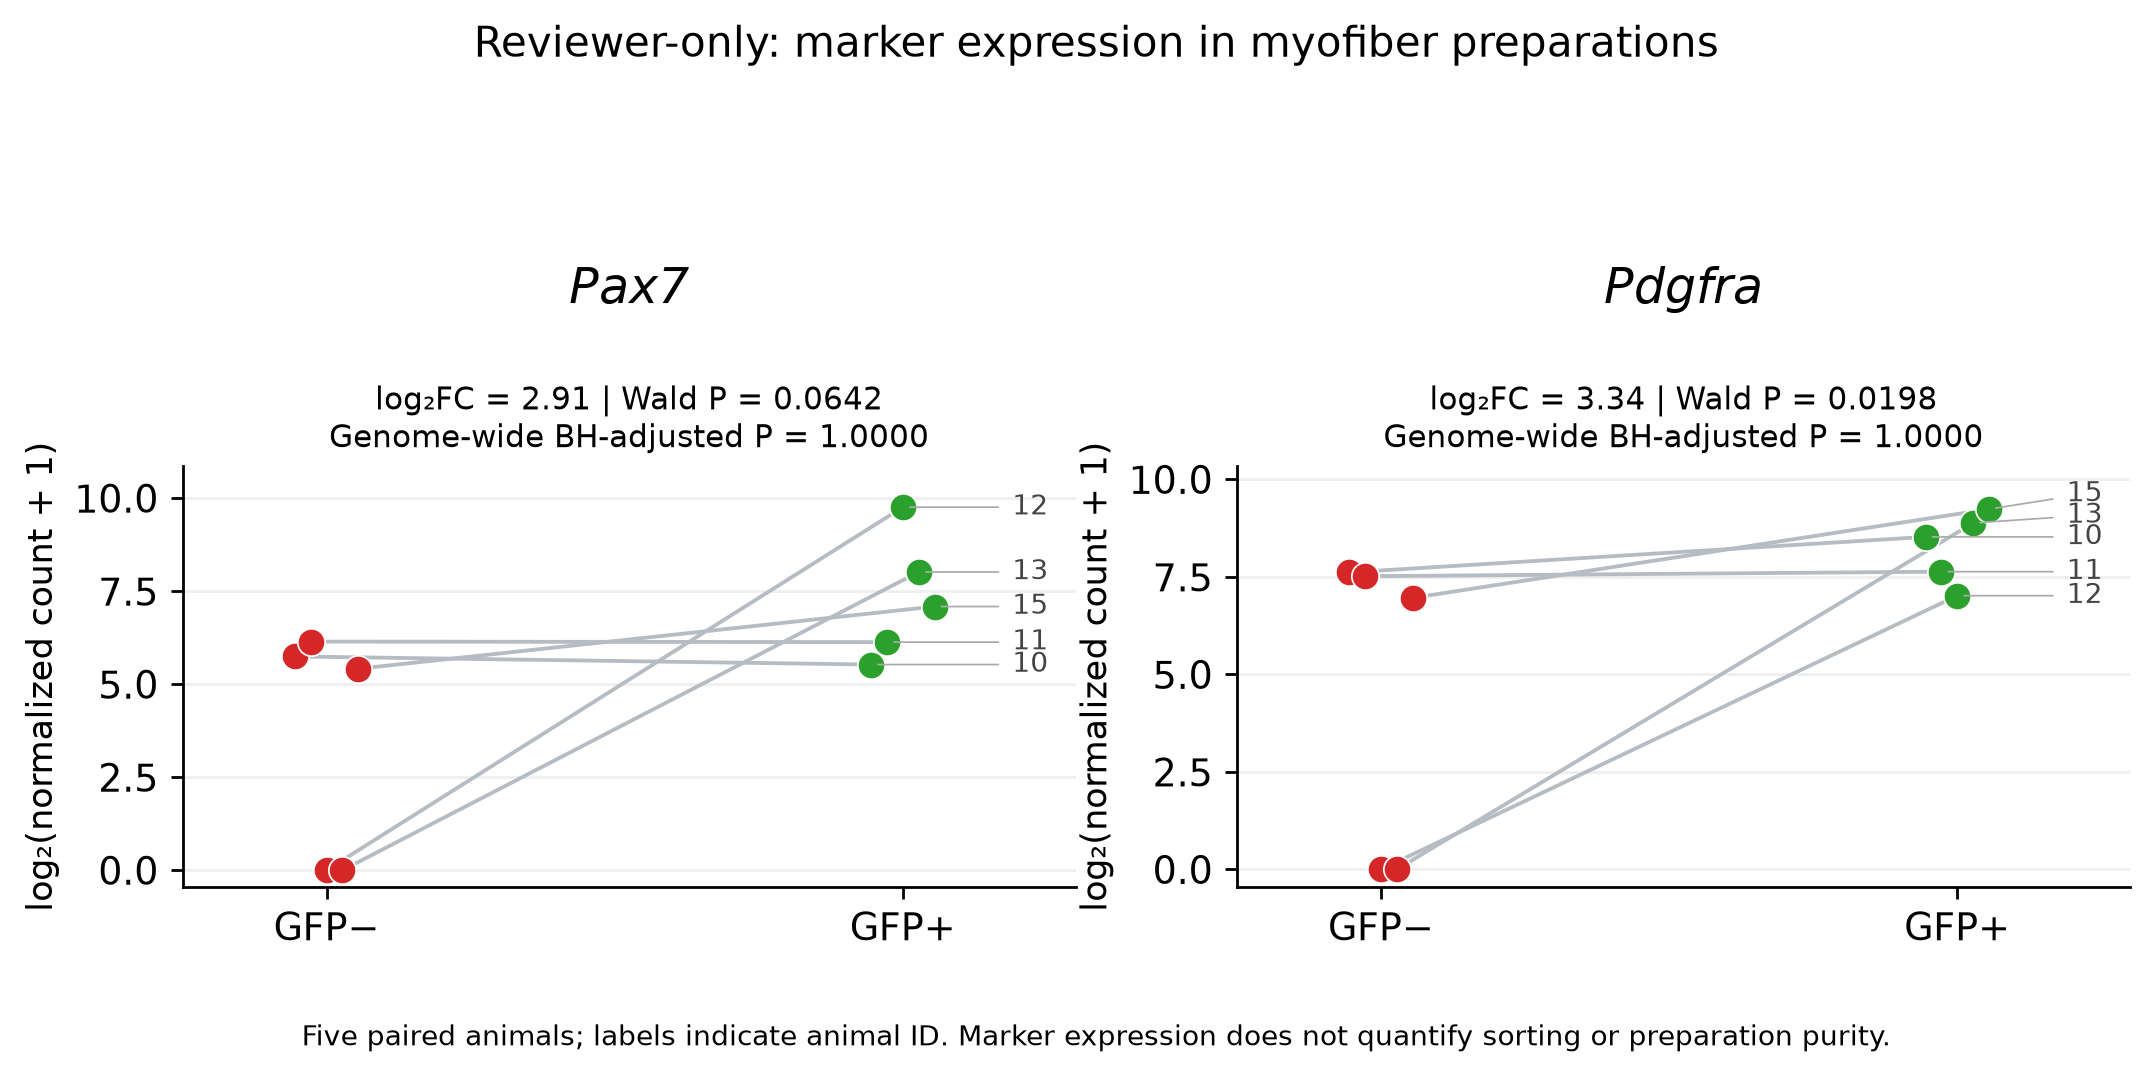

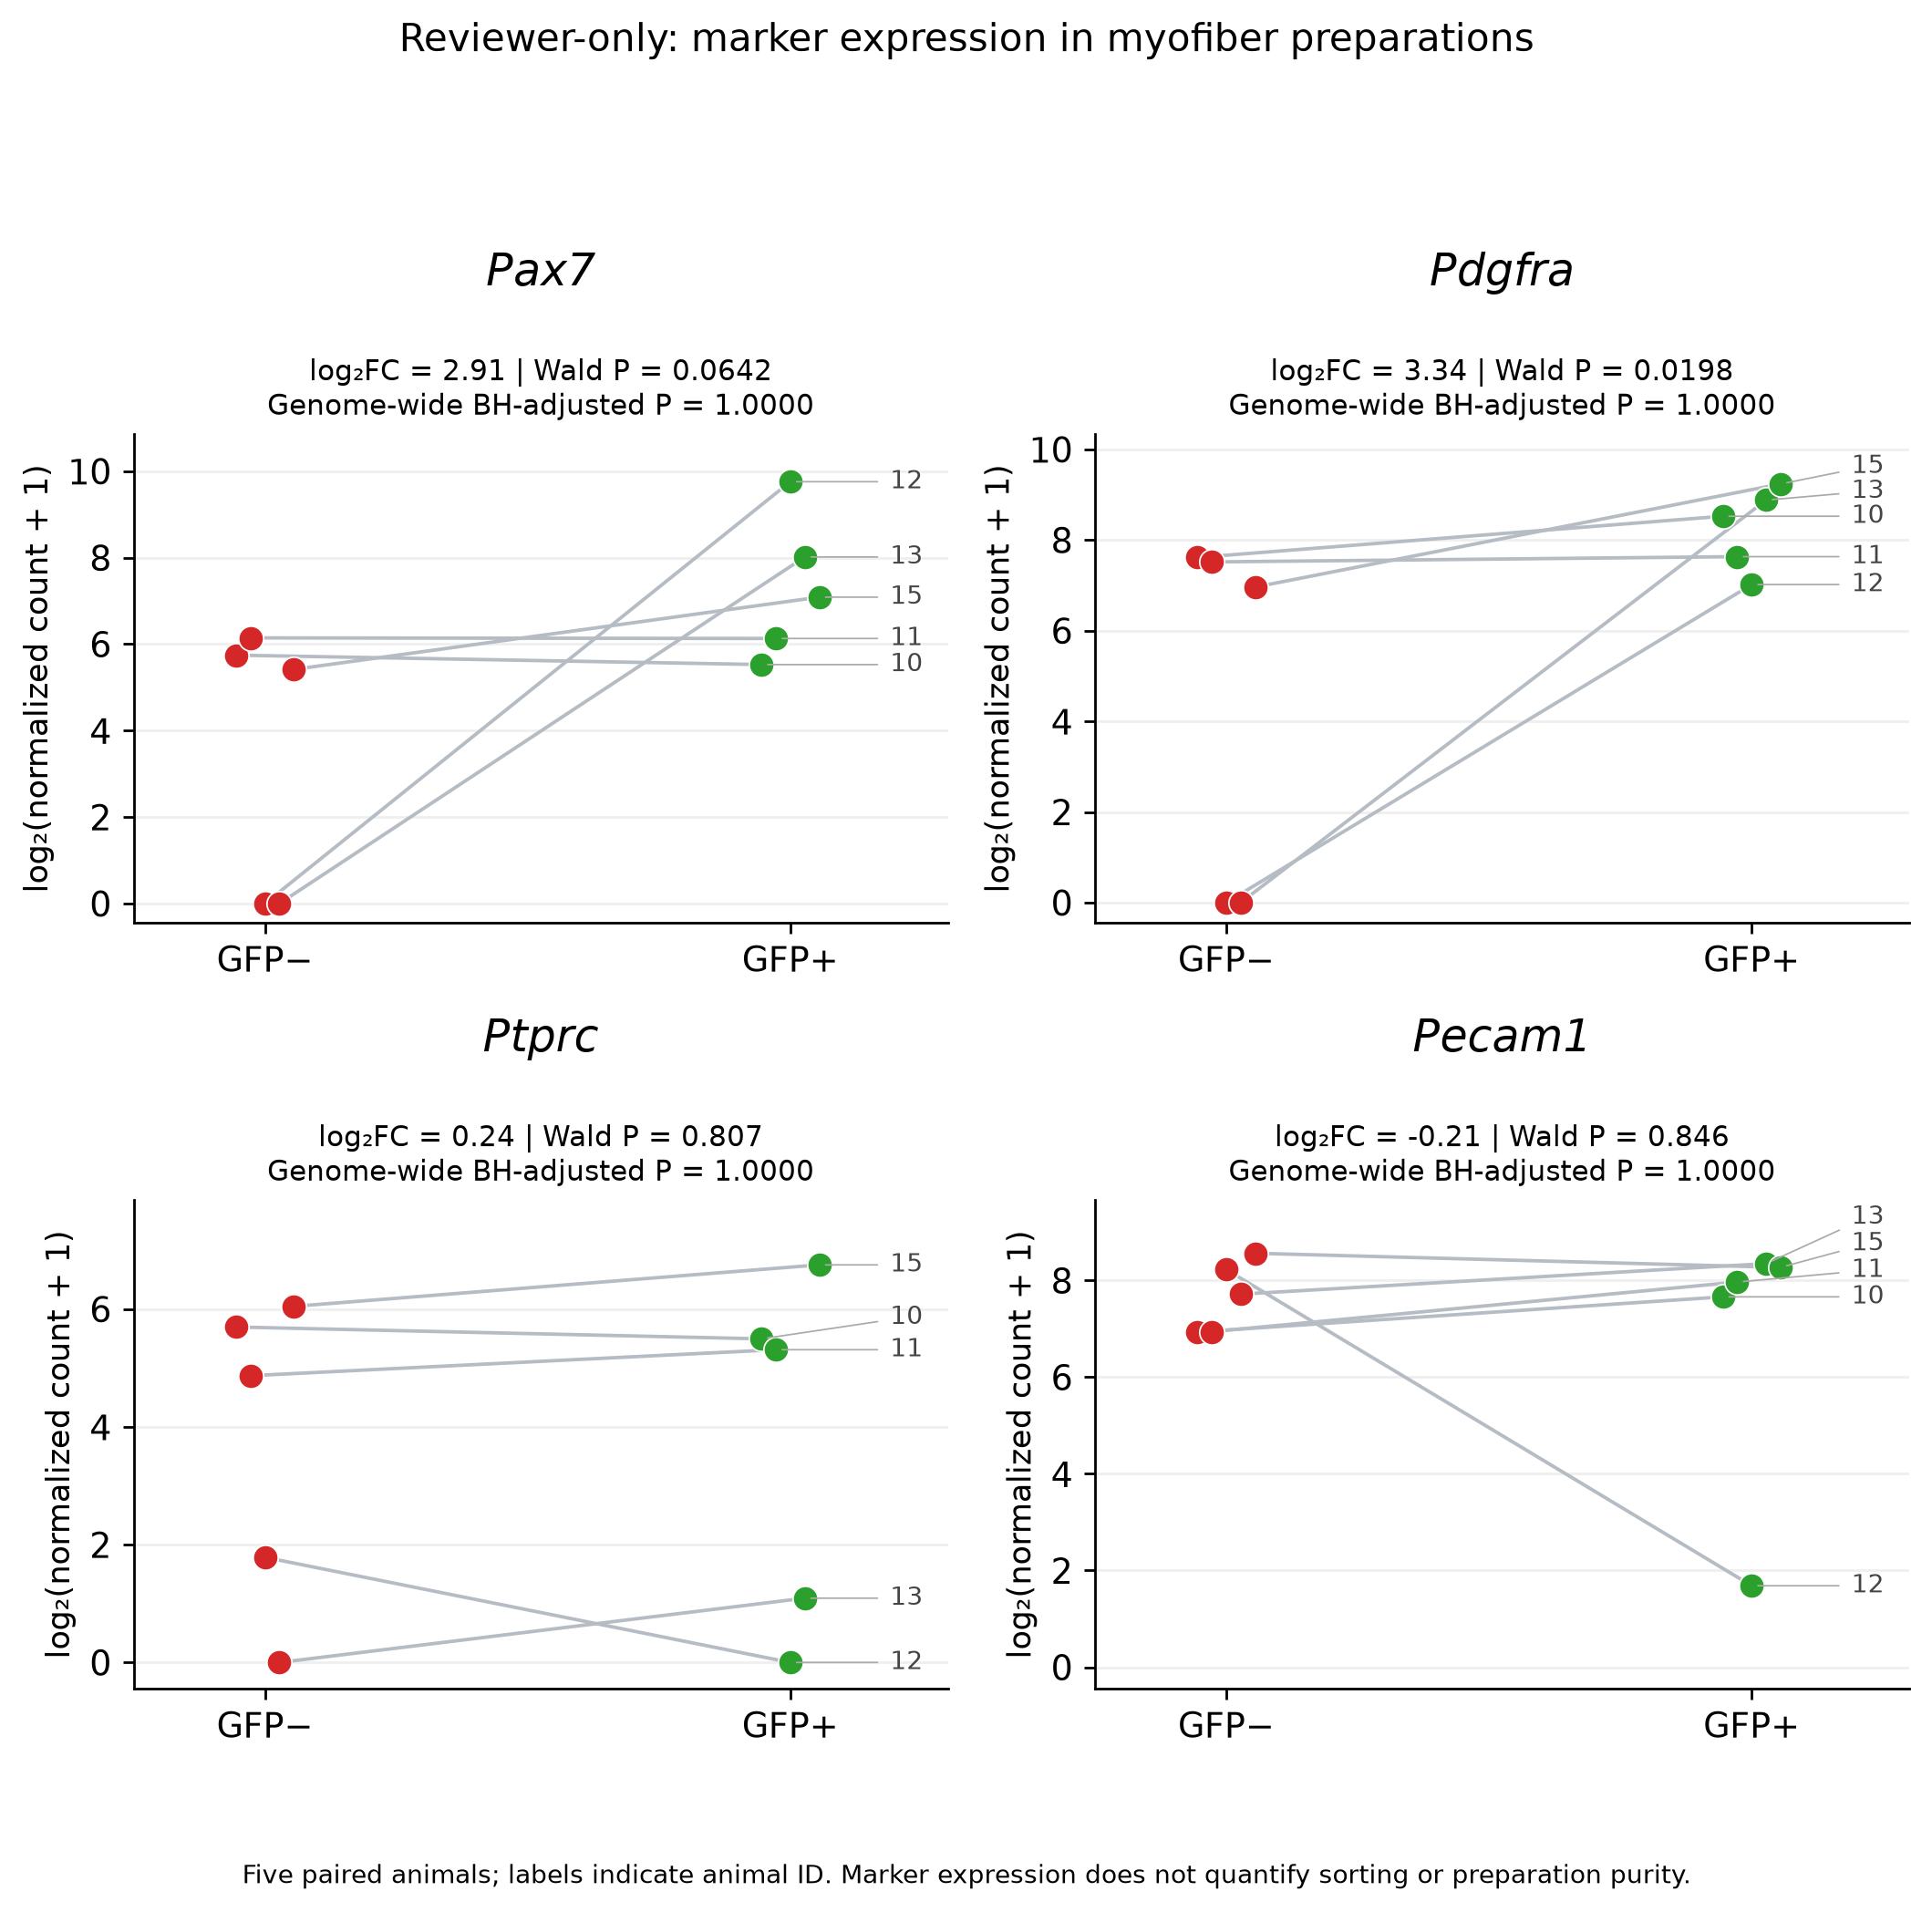

In [11]:
MARKERS = ['Pax7','Pdgfra','Ptprc','Pecam1']
marker_roles = {'Pax7':'MuSC-associated', 'Pdgfra':'FAP-associated',
                'Ptprc':'Leukocyte-associated', 'Pecam1':'Endothelial-associated'}
marker_rows = []
marker_stats = []
for symbol in MARKERS:
    matches = de[de.symbol == symbol]
    if len(matches) != 1:
        raise ValueError(f'{symbol}: expected one gene ID, found {len(matches)}')
    row = matches.iloc[0]
    for animal in sorted(a.animal.unique()):
        for condition in ['negative','positive']:
            sample = animal + '_' + condition
            value = float(norm_counts.loc[row.gene_id, sample])
            marker_rows.append({'symbol':symbol,'gene_id':row.gene_id,
                'animal':animal,'condition':condition,'normalized_count':value,
                'log2_normalized_count_plus1':float(np.log2(value+1))})
    marker_stats.append({'symbol':symbol,'gene_id':row.gene_id,
        'marker_context':marker_roles[symbol], 'log2FC_GFPpos_vs_GFPneg':row.log2FoldChange,
        'nominal_Wald_P':row.pvalue,'genome_wide_BH_adjusted_P':row.padj})
marker_data = pd.DataFrame(marker_rows)
marker_results = pd.DataFrame(marker_stats)
for symbol in MARKERS:
    pair_table = marker_data[marker_data.symbol == symbol].pivot(
        index='animal',columns='condition',values='normalized_count')
    marker_results.loc[marker_results.symbol == symbol,'animals_higher_in_GFPpos'] = int(
        (pair_table.positive > pair_table.negative).sum())
marker_data.to_csv(OUT / 'review_only_marker_expression.csv',index=False)
marker_results.to_csv(OUT / 'review_only_marker_statistics.csv',index=False)
print(marker_results.to_string(index=False))

def marker_panel(symbols, name):
    cols=2; rows=(len(symbols)+1)//2
    fig, axes=plt.subplots(rows,cols,figsize=(8.6,4.2*rows),squeeze=False)
    for ax, symbol in zip(axes.flat,symbols):
        subset=marker_data[marker_data.symbol == symbol]
        animals=sorted(subset.animal.unique())
        offsets=dict(zip(animals,np.linspace(-.055,.055,len(animals))))
        label_points=[]
        for animal, pair in subset.groupby('animal'):
            pair=pair.set_index('condition').loc[['negative','positive']]
            xpos=np.array([0.,1.])+offsets[animal]
            yy=pair.log2_normalized_count_plus1.to_numpy()
            ax.plot(xpos,yy,color='#B6BCC4',lw=1.1,zorder=1)
            for j,color in enumerate(['#D62728','#2CA02C']):
                ax.scatter(xpos[j],yy[j],s=62,c=color,edgecolor='white',linewidth=.5,zorder=3)
            label_points.append((float(yy[1]),float(xpos[1]),animal))
        previous=-1.0
        for actual_y,actual_x,animal in sorted(label_points):
            label_y=max(actual_y,previous+.55)
            previous=label_y
            ax.annotate(animal,(actual_x,actual_y),xytext=(1.19,label_y),
                fontsize=8,va='center',color='#444444',
                arrowprops=dict(arrowstyle='-',color='#AAAAAA',lw=.5))
        stats=marker_results[marker_results.symbol == symbol].iloc[0]
        ax.set_title(symbol,fontstyle='italic',fontsize=14,pad=47)
        padj=stats.genome_wide_BH_adjusted_P
        adj_text='NA' if pd.isna(padj) else f'{padj:.4f}'
        ax.text(.5,1.02,f'log₂FC = {stats.log2FC_GFPpos_vs_GFPneg:.2f} | Wald P = {stats.nominal_Wald_P:.3g}\n'
                f'Genome-wide BH-adjusted P = {adj_text}',transform=ax.transAxes,
                ha='center',va='bottom',fontsize=9)
        ax.set_xticks([0,1],['GFP−','GFP+'])
        ax.set_xlim(-.25,1.3)
        ax.set_ylim(-.45, max(subset.log2_normalized_count_plus1)+1.1)
        ax.set_ylabel('log₂(normalized count + 1)',fontsize=10)
        ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
    for ax in list(axes.flat)[len(symbols):]:ax.set_visible(False)
    fig.suptitle('Reviewer-only: marker expression in myofiber preparations',fontsize=12,y=.99)
    fig.tight_layout(rect=(0,.07,1,.88 if rows==1 else .93))
    fig.text(.5,.018,'Five paired animals; labels indicate animal ID. Marker expression does not quantify sorting or preparation purity.',
             ha='center',fontsize=8)
    save(fig,name)
marker_panel(['Pax7','Pdgfra'],'Review_only_Pax7_Pdgfra')
marker_panel(MARKERS,'Review_only_four_markers')


## Optional convergence sensitivity


In [12]:
# Set True only to reproduce the documented numerical-convergence sensitivity analysis.
# This is NOT the primary result and is not used to choose settings or a seed.
RUN_CONVERGENCE_SENSITIVITY = False
if RUN_CONVERGENCE_SENSITIVITY:
    failed_stable = set(pd.Index(failed_ids).str.replace(r'\.\d+$', '', regex=True))
    sensitivity_ranks = ranks[~ranks.index.isin(failed_stable)]
    sensitivity_universe = set(sensitivity_ranks.index)
    sensitivity_sets = {k:v for k,v in sets.items()
        if GSEA_MIN_SIZE <= len(set(v) & sensitivity_universe) <= GSEA_MAX_SIZE}
    sensitivity = gp.prerank(rnk=sensitivity_ranks, gene_sets=sensitivity_sets,
        threads=THREADS, min_size=GSEA_MIN_SIZE, max_size=GSEA_MAX_SIZE,
        method='multilevel', sample_size=GSEA_SAMPLE_SIZE, permutation_num=1000,
        eps=1e-10, seed=SEED, weight=1, outdir=None, verbose=True, no_plot=True)
    sensitivity_g = sensitivity.res2d.copy()
    sensitivity_g['BH_padj_all_pathways'] = false_discovery_control(
        pd.to_numeric(sensitivity_g['NOM p-val']).to_numpy(), method='bh')
    sensitivity_g.to_csv(OUT / 'GSEA_convergence_sensitivity.csv', index=False)
    sensitivity_sig = set(sensitivity_g.Term[sensitivity_g.BH_padj_all_pathways < ALPHA])
    print('Primary significant sets retained after removing flagged genes:',
          len(set(sg.Term) & sensitivity_sig), '/', len(sg))
